In [ ]:
#1

!pip install -q wfdb numpy pandas scipy matplotlib seaborn scikit-learn tensorflow

In [ ]:
print("helo")

# Step 1:- Install dependencies

In [ ]:
#2

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import wfdb
import tensorflow as tf

from scipy.signal import butter,filtfilt
from sklearn.metrics import (classification_report,confusion_matrix,accuracy_score)


In Python's scipy.signal library, butter() and filtfilt() are used for filtering signals and removing unwanted noise.

1. What is butter()?
butter() creates a Butterworth filter.

A Butterworth filter is used to remove unwanted frequencies from a signal while maintaining a smooth frequency response.

For ECG signals, unwanted noise can come from:
- Baseline wandering (slow fluctuations).
- Muscle activity.
- Electrical interference (50 Hz noise).

2. What is filtfilt()?
filtfilt() applies the filter twice:
1. First, it filters the signal in the forward direction.
2. Then, it reverses the signal and filters it again in the backward direction.
The main advantage is zero-phase filtering.

It avoids the phase shift that normally occurs when applying a standard filter in one direction.

# step 2: make project directories in colab

In [ ]:
#3

#creating project directories

BASE_DIR="/content/ECG-Guard"

directories=[
    "dataset/raw",
    "dataset/processed",
    "models",
    "reports",
    "src"
]

for directory in directories:
  os.makedirs(os.path.join(BASE_DIR,directory),exist_ok=True)

print("Project directories created")


!ls -R /content/ECG-Guard


Project directories created
/content/ECG-Guard:
dataset  models  reports  src

/content/ECG-Guard/dataset:
processed  raw

/content/ECG-Guard/dataset/processed:

/content/ECG-Guard/dataset/raw:

/content/ECG-Guard/models:

/content/ECG-Guard/reports:

/content/ECG-Guard/src:


#step 4 downloading the MIT_BIH dataset

We will use the official **MIT-BIH Arrhythmia Database.**

It contains 48 recordings from 47 subjects, sampled at 360 Hz, with expert-reviewed heartbeat annotations. Each recording has signal, header and annotation files.

In [ ]:
#4

#downloading MIT_BIH dataset

RAW_DIR="content/mitdb"

os.makedirs(RAW_DIR,exist_ok=True)

print("Downloading MIT_BIH database...")

wfdb.dl_database("mitdb",dl_dir=RAW_DIR)

print("dataset downloaded successfully")

print("files downloaded: ",len(os.listdir(RAW_DIR)))

Generating record list for: 100
Generating record list for: 101
Generating record list for: 102
Generating record list for: 103
Generating record list for: 104
Generating record list for: 105
Generating record list for: 106
Generating record list for: 107
Generating record list for: 108
Generating record list for: 109
Generating record list for: 111
Generating record list for: 112
Generating record list for: 113
Generating record list for: 114
Generating record list for: 115
Generating record list for: 116
Generating record list for: 117
Generating record list for: 118
Generating record list for: 119
Generating record list for: 121
Generating record list for: 122
Generating record list for: 123
Generating record list for: 124
Generating record list for: 200
Generating record list for: 201
Generating record list for: 202
Generating record list for: 203
Generating record list for: 205
Generating record list for: 207
Generating record list for: 208
Generating record list for: 209
Generati

wfdb.dl_database() is a function from the Python WFDB library used to download an entire PhysioNet database or selected records from it to your local computer.

In [ ]:
#5

print(os.listdir(RAW_DIR)[:20])

['203.atr', '101.hea', '213.atr', '102.dat', '223.atr', '115.dat', '119.dat', '207.dat', '124.atr', '109.hea', '117.hea', '210.hea', '208.dat', '214.atr', '117.atr', '230.dat', '123.atr', '232.dat', '220.hea', '210.dat']


| Extension | Meaning |
|-----------|---------|
| `.dat` | Actual ECG signal |
| `.hea` | Recording information |
| `.atr` | Expert heartbeat annotations |

We are using the **AAMI five-class grouping** for ECG heartbeat classification.

| Class | Meaning | MIT-BIH Annotation Symbols |
|-------|---------|----------------------------|
| N | Normal | N, L, R, e, j |
| S | Supraventricular ectopic | A, a, J, S |
| V | Ventricular ectopic | V, E |
| F | Fusion beat | F |
| Q | Unknown / Paced | /, f, Q, U |

These are standard groupings used in ECG classification research.

AAMI stands for Association for the Advancement of Medical Instrumentation.

It is an organisation that develops standards for medical devices and healthcare technology.

In your ECG-Guard project, AAMI is important because it provides a standard way to group ECG heartbeats into different categories for arrhythmia classification.

In [ ]:
#6

#define AAMI class

CLASS_MAP={
    "N":0,
    "L":0,
    "R":0,
    "e":0,
    "j":0,

    "A":1,
    "a":1,
    "J":1,
    "S":1,

    "V":2,
    "E":2,

    "F":3,

    "/":4,
    "f":4,
    "Q":4,
    "U":4
}

CLASS_NAMES=[
    "Normal",
    "Supraventricular ",
    "Ventricular",
    "Fusion Beat",
    "Unknown"
]

**What is Arrhythmia?**
Arrhythmia is an abnormality in the rhythm or rate of the heartbeat.

#step 5 patient independent split

In [ ]:
#7

# ==========================================
# STEP 4: PATIENT-INDEPENDENT SPLIT
# ==========================================

DS1 = [
    "101", "106", "108", "109", "112",
    "114", "115", "116", "118", "119",
    "122", "124", "203", "205", "207",
    "208", "209", "215", "220", "223", "230"
]

DS2 = [
    "100", "103", "105", "111", "113",
    "117", "121", "123", "200", "210",
    "212", "213", "214", "219", "221",
    "222", "228", "231", "232", "233", "234"
]

print("Training records:", len(DS1))
print("Testing records:", len(DS2))

assert set(DS1).isdisjoint(set(DS2))

print("No overlapping records.")

Training records: 21
Testing records: 21
No overlapping records.


#STEP 5 :- Visualise an ECG recording

In [ ]:
#8

record=wfdb.rdrecord(os.path.join(RAW_DIR,"100"))

#wfdb.rdrecord() reads an ECG recording.

annotation=wfdb.rdann(
    os.path.join(RAW_DIR,"100"),
    "atr"
)
#wfdb.rdann() reads annotations.
#"atr" specifies the annotation file extension.

#--------------extract The ECG signa--------------------------------
signal=record.p_signal[:,0]
#-------------------------------------------------------------------

sampling_rate=record.fs #fs-->sampling frequency

print("Sampling rate:",sampling_rate)
print("Signal shape:",signal.shape)
print("Signal Channels: ",record.sig_name)
print("Number of annotations: ",len(annotation.sample))

print("First 10 annotation symbols: ")
print(annotation.symbol[:10])


Sampling rate: 360
Signal shape: (650000,)
Signal Channels:  ['MLII', 'V5']
Number of annotations:  2274
First 10 annotation symbols: 
['+', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'A', 'N']


now visualise the first 10 seconds

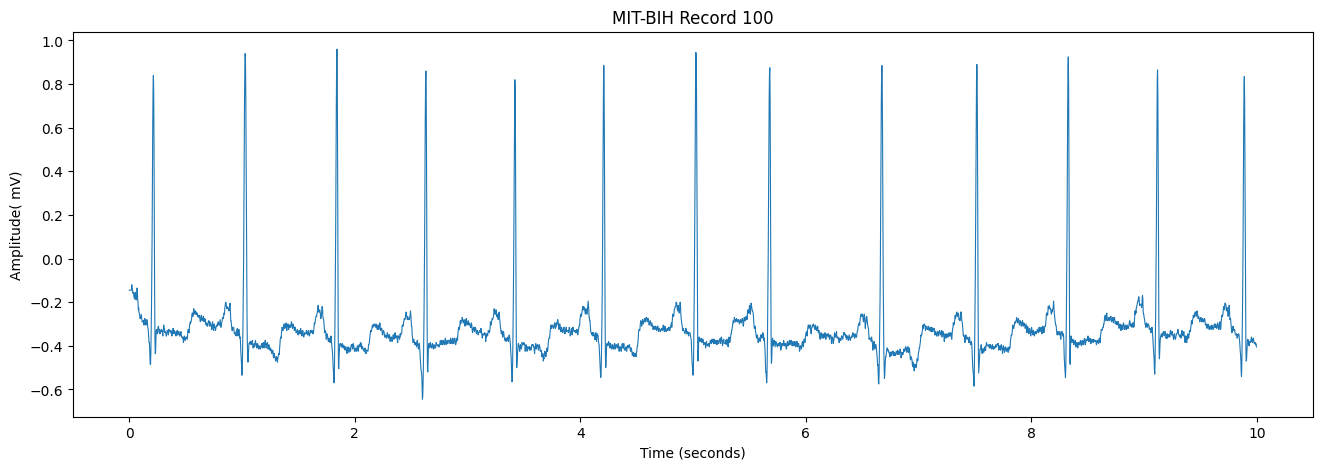

In [ ]:
#9

duration=10

samples=int(duration*sampling_rate)

time_axis=np.arange(samples)/sampling_rate

plt.figure(figsize=(16,5))
plt.plot(
    time_axis,
    signal[:samples],
    linewidth=0.8
)

plt.title("MIT-BIH Record 100")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude( mV)")
plt.show()



#Step 6. Preprocess the ECG signals
Real ECG signals contain noise. We will apply a Butterworth bandpass filter between 0.5 Hz and 40 Hz.

Then we will extract a heartbeat segment around every annotated beat.

Our segmentation:
- 200 ms before the annotated heartbeat.
- 400 ms after the annotated heartbeat.
- At 360 Hz, this gives 216 samples per heartbeat.

In [ ]:
#10

from scipy.signal import butter, sosfiltfilt

def filter_ecg(signal, fs=360):
    sos = butter(
        3,
        [0.5, 40],
        btype="bandpass",
        fs=fs,
        output="sos"
    )

    filtered = sosfiltfilt(sos, signal)

    return filtered

In [ ]:
#11

import numpy as np

def normalize_beats(beat):
    mean = np.mean(beat)
    std = np.std(beat)

    if not np.isfinite(std) or std < 1e-8:
        return None

    normalized = (beat - mean) / std

    if not np.all(np.isfinite(normalized)):
        return None

    return normalized

In [ ]:
#12

def extract_beats(signal, annotation, fs=360):

    filtered = filter_ecg(signal, fs)

    before = int(0.2 * fs)
    after = int(0.4 * fs)

    beats = []
    labels = []
    rr_features = []

    # Collect valid heartbeat annotations

    valid_events = []

    for sample, symbol in zip(
        annotation.sample,
        annotation.symbol
    ):

        if symbol not in CLASS_MAP:
            continue

        sample = int(sample)

        start = sample - before
        end = sample + after

        if start < 0 or end > len(filtered):
            continue

        valid_events.append((sample, symbol))

    if len(valid_events) < 2:

        return (
            np.empty((0, before + after), dtype=np.float32),
            np.empty((0,), dtype=np.int64),
            np.empty((0, 4), dtype=np.float32)
        )

    # Calculate RR intervals

    beat_samples = np.array(
        [event[0] for event in valid_events]
    )

    rr_intervals = np.diff(beat_samples) / fs

    rr_median = float(np.median(rr_intervals))

    if not np.isfinite(rr_median) or rr_median <= 0:
        rr_median = 1.0

    # Extract each heartbeat

    for idx, (sample, symbol) in enumerate(valid_events):

        start = sample - before
        end = sample + after

        beat = filtered[start:end]

        # Normalize heartbeat

        beat = normalize_beats(beat)

        if beat is None:
            continue

        # Previous RR

        if idx > 0:
            pre_rr_raw = rr_intervals[idx - 1]
        else:
            pre_rr_raw = rr_median

        # Next RR

        if idx < len(rr_intervals):
            post_rr_raw = rr_intervals[idx]
        else:
            post_rr_raw = rr_median

        # Prevent extreme values

        pre_rr = np.clip(pre_rr_raw, 0.2, 3.0)
        post_rr = np.clip(post_rr_raw, 0.2, 3.0)

        # Relative RR features

        pre_ratio = np.clip(
            pre_rr_raw / rr_median,
            0.25,
            4.0
        )

        post_ratio = np.clip(
            post_rr_raw / rr_median,
            0.25,
            4.0
        )

        beats.append(beat)

        labels.append(CLASS_MAP[symbol])

        rr_features.append([
            pre_rr,
            post_rr,
            pre_ratio,
            post_ratio
        ])

    return (
        np.asarray(beats, dtype=np.float32),
        np.asarray(labels, dtype=np.int64),
        np.asarray(rr_features, dtype=np.float32)
    )

We have now created three important functions:
1. filter_ecg() – removes unwanted signal frequencies.
2. normalize_beat() – standardizes individual heartbeat segments.
3. extract_beats() – extracts heartbeat segments and assigns their classes.

SOS stands for Second-Order Sections.

Instead of representing the entire filter as one large set of coefficients, SciPy represents it as multiple smaller filter sections.

#step 7:- extract the training and testing data



In [ ]:
#13
import os
import wfdb
import numpy as np

def process_records(record_list):

    all_beats = []
    all_labels = []
    all_groups = []
    all_rr_features = []

    failed_records = []

    for record_id in record_list:

        print(f"\nProcessing record: {record_id}")

        record_path = os.path.join(RAW_DIR, record_id)

        try:

            record = wfdb.rdrecord(record_path)

            annotation = wfdb.rdann(
                record_path,
                "atr"
            )

            fs = record.fs

            # Select MLII lead

            lead_names = [
                name.upper()
                for name in record.sig_name
            ]

            lead_index = next(
                (
                    i for i, name in enumerate(lead_names)
                    if "MLII" in name
                ),
                0
            )

            signal = record.p_signal[:, lead_index]

            # Extract waveform, labels and RR features

            beats, labels, rr_features = extract_beats(
                signal,
                annotation,
                fs
            )

            if len(beats) == 0:

                failed_records.append(record_id)
                continue

            all_beats.extend(beats)
            all_labels.extend(labels)

            all_groups.extend(
                [record_id] * len(labels)
            )

            all_rr_features.extend(rr_features)

            print("Selected lead:", record.sig_name[lead_index])
            print("Extracted beats:", len(beats))

        except Exception as error:

            print("Error:", error)

            failed_records.append(record_id)

    X = np.asarray(
        all_beats,
        dtype=np.float32
    )

    y = np.asarray(
        all_labels,
        dtype=np.int64
    )

    groups = np.asarray(all_groups)

    RR = np.asarray(
        all_rr_features,
        dtype=np.float32
    ).reshape(-1, 4)

    print("\n========== PROCESSING SUMMARY ==========")

    print("Total heartbeats:", len(X))
    print("ECG shape:", X.shape)
    print("RR feature shape:", RR.shape)
    print("Label shape:", y.shape)

    print("Failed records:", failed_records)

    return X, y, groups, RR

In [ ]:
#14

# Process DS1 training records

X_train_all, y_train_all, groups_train, RR_train_all = (
    process_records(DS1)
)

# Process DS2 testing records

X_test, y_test, groups_test, RR_test_all = (
    process_records(DS2)
)

print("\n========== FINAL DATASET ==========")

print("Training ECG:", X_train_all.shape)
print("Training RR:", RR_train_all.shape)

print("Testing ECG:", X_test.shape)
print("Testing RR:", RR_test_all.shape)

print("Training records:", len(np.unique(groups_train)))
print("Testing records:", len(np.unique(groups_test)))

assert set(groups_train).isdisjoint(set(groups_test))


Processing record: 101
Selected lead: MLII
Extracted beats: 1865

Processing record: 106
Selected lead: MLII
Extracted beats: 2027

Processing record: 108
Selected lead: MLII
Extracted beats: 1763

Processing record: 109
Selected lead: MLII
Extracted beats: 2531

Processing record: 112
Selected lead: MLII
Extracted beats: 2538

Processing record: 114
Selected lead: MLII
Extracted beats: 1879

Processing record: 115
Selected lead: MLII
Extracted beats: 1952

Processing record: 116
Selected lead: MLII
Extracted beats: 2411

Processing record: 118
Selected lead: MLII
Extracted beats: 2277

Processing record: 119
Selected lead: MLII
Extracted beats: 1987

Processing record: 122
Selected lead: MLII
Extracted beats: 2475

Processing record: 124
Selected lead: MLII
Extracted beats: 1618

Processing record: 203
Selected lead: MLII
Extracted beats: 2980

Processing record: 205
Selected lead: MLII
Extracted beats: 2655

Processing record: 207
Selected lead: MLII
Extracted beats: 1859

Processin

#step 8:- checking class distribution


Training Dataset - 4 Classes
Normal : 44217
Supraventricular : 816
Ventricular : 3590
Fusion Beat : 412


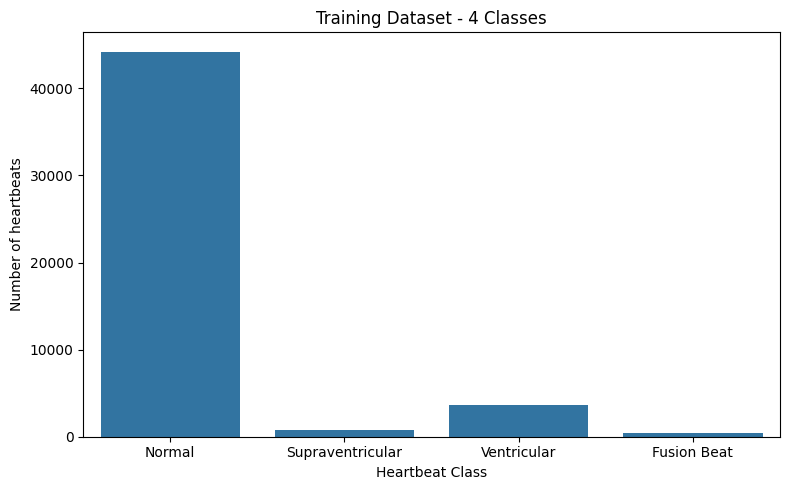


Testing Dataset - 4 Classes
Normal : 42182
Supraventricular : 1782
Ventricular : 3201
Fusion Beat : 387


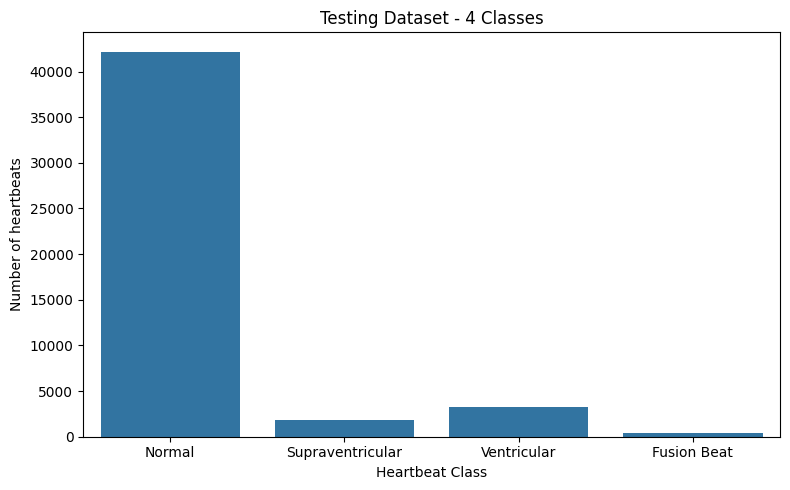

In [ ]:

#15

def show_distribution(labels, title):

    # Convert to numpy array
    labels = np.asarray(labels)

    # Keep only four classes (0, 1, 2, 3)
    labels = labels[labels < 4]

    counts = pd.Series(labels).value_counts()

    counts = counts.reindex(
        range(4),
        fill_value=0
    )

    print("\n" + title)

    for i, count in counts.items():

        print(
            CLASS_NAMES[i],
            ":",
            count
        )

    plt.figure(figsize=(8, 5))

    sns.barplot(
        x=CLASS_NAMES,
        y=counts.values
    )

    plt.title(title)
    plt.ylabel("Number of heartbeats")
    plt.xlabel("Heartbeat Class")

    plt.tight_layout()
    plt.show()


show_distribution(
    y_train_all,
    "Training Dataset - 4 Classes"
)

show_distribution(
    y_test,
    "Testing Dataset - 4 Classes"
)


here is class imbalance

The biggest problem is the Unknown category.
- Normal has 44,217 samples.
- Unknown has only 8 samples.
- Normal has approximately 5,527 times more samples than Unknown.
If we train directly on this dataset, the model may become biased towards Normal heartbeats.
2. What should we do?
I recommend a combination of three techniques:
1. Class weighting: Give more importance to minority classes during training.
2. Oversampling: Increase the representation of minority classes in the training data.
3. Careful evaluation: Measure precision, recall and F1-score for every class.
However, there is one important issue: eight Unknown examples are not enough to train or evaluate a reliable Unknown classifier.

We should not artificially create thousands of Unknown samples from eight original examples and then claim that the model has learned the class.

ECG-Guard — Four-Class Classification
N — Normal
44,217

S — Supraventricular
816

V — Ventricular
3,590

F — Fusion
412


Q — Unknown / paced

Excluded from this initial model because only 8 examples are available in the current split.

In [ ]:
#16

# Keep only N, S, V and F

train_mask = y_train_all != 4
test_mask = y_test != 4

X_train_all_4 = X_train_all[train_mask]
y_train_all_4 = y_train_all[train_mask]

groups_train_4 = groups_train[train_mask]

RR_train_all_4 = RR_train_all[train_mask]

X_test_4 = X_test[test_mask]
y_test_4 = y_test[test_mask]

RR_test_4 = RR_test_all[test_mask]

CLASS_NAMES = [
    "Normal",
    "Supraventricular",
    "Ventricular",
    "Fusion Beat"
]

print("Training ECG:", X_train_all_4.shape)
print("Training RR:", RR_train_all_4.shape)

print("Testing ECG:", X_test_4.shape)
print("Testing RR:", RR_test_4.shape)

Training ECG: (49035, 216)
Training RR: (49035, 4)
Testing ECG: (47552, 216)
Testing RR: (47552, 4)


In [ ]:
#16 A
# Check class distribution for each patient

record_class_counts = pd.crosstab(
    groups_train_4,
    y_train_all_4
)

record_class_counts = record_class_counts.reindex(
    columns=[0, 1, 2, 3],
    fill_value=0
)

record_class_counts.columns = CLASS_NAMES

print("Patient-wise class distribution:")
display(record_class_counts)

print("\nNumber of patients containing each class:")

print(
    (record_class_counts > 0).sum()
)


Patient-wise class distribution:


,Normal,Supraventricular,Ventricular,Fusion Beat
row_0,,,,
101,1860,3,0,0
106,1507,0,520,0
108,1740,4,17,2
109,2491,0,38,2
112,2536,2,0,0
114,1820,12,43,4
115,1952,0,0,0
116,2301,1,109,0
118,2165,96,16,0



Number of patients containing each class:
Normal              21
Supraventricular    15
Ventricular         16
Fusion Beat          9
dtype: int64


In [ ]:
#17

from sklearn.model_selection import GroupShuffleSplit

# Original DS1 training data

X_all = X_train_all_4

y_all = y_train_all_4

groups_all = groups_train_4

rr_all = RR_train_all_4

# Overall class distribution

total_counts = np.bincount(
    y_all,
    minlength=4
)

# Generate candidate patient-independent splits

splitter = GroupShuffleSplit(
    n_splits=5000,
    test_size=0.20,
    random_state=42
)

candidates = []

for split_number, (tr_idx, val_idx) in enumerate(
    splitter.split(
        X_all,
        y_all,
        groups_all
    )
):

    train_counts = np.bincount(
        y_all[tr_idx],
        minlength=4
    )

    val_counts = np.bincount(
        y_all[val_idx],
        minlength=4
    )

    # All classes must be represented in both datasets

    if np.any(train_counts == 0) or np.any(val_counts == 0):
        continue

    val_fraction = len(val_idx) / len(y_all)

    # Expected class distribution in validation

    expected_counts = total_counts * val_fraction

    # Measure class distribution difference

    relative_error = np.mean(
        np.abs(val_counts - expected_counts) /
        np.maximum(expected_counts, 1)
    )

    # Penalize validation sizes far from 20%

    size_error = abs(val_fraction - 0.20)

    score = relative_error + 2 * size_error

    candidates.append({

        "score": score,

        "train_idx": tr_idx,

        "val_idx": val_idx,

        "train_counts": train_counts,

        "val_counts": val_counts,

        "val_patients": len(
            np.unique(groups_all[val_idx])
        )

    })


# Check whether sufficiently supported minority-class
# validation splits are available.

eligible = [

    candidate for candidate in candidates

    if candidate["val_counts"][1] >= 30
    and candidate["val_counts"][3] >= 20

]

if eligible:

    search_pool = eligible

else:

    search_pool = candidates

    print(
        "WARNING: No split met the minimum "
        "minority-class validation thresholds."
    )


if not search_pool:

    raise ValueError(
        "No valid patient-independent split found."
    )


# Select the best candidate

best_split = min(
    search_pool,
    key=lambda x: x["score"]
)

train_idx = best_split["train_idx"]

val_idx = best_split["val_idx"]


# Create datasets

X_train = X_all[train_idx]

y_train = y_all[train_idx]

X_val = X_all[val_idx]

y_val = y_all[val_idx]


# Corresponding RR features

RR_train = rr_all[train_idx]

RR_val = rr_all[val_idx]


# Patient independence verification

assert set(groups_all[train_idx]).isdisjoint(
    set(groups_all[val_idx])
)


# Display results

print("\n========== OPTIMIZED SPLIT ==========")

print("Training samples:", len(train_idx))

print("Validation samples:", len(val_idx))

print(
    "Training patients:",
    len(np.unique(groups_all[train_idx]))
)

print(
    "Validation patients:",
    len(np.unique(groups_all[val_idx]))
)

print("\nTraining distribution:")

for i, name in enumerate(CLASS_NAMES):

    print(name, ":", best_split["train_counts"][i])


print("\nValidation distribution:")

for i, name in enumerate(CLASS_NAMES):

    print(name, ":", best_split["val_counts"][i])


print("\nSelected split score:", best_split["score"])

print("\nPatient-independent splitting verified!")


========== OPTIMIZED SPLIT ==========
Training samples: 38290
Validation samples: 10745
Training patients: 16
Validation patients: 5

Training distribution:
Normal : 34460
Supraventricular : 626
Ventricular : 2819
Fusion Beat : 385

Validation distribution:
Normal : 9757
Supraventricular : 190
Ventricular : 771
Fusion Beat : 27

Selected split score: 0.2358674539162442

Patient-independent splitting verified!


In [ ]:
# Check selected recording IDs

train_records = set(
    map(str, groups_train_4[train_idx])
)

val_records = set(
    map(str, groups_train_4[val_idx])
)

print("Training recordings:")
print(sorted(train_records))

print("\nValidation recordings:")
print(sorted(val_records))

print("\nRecord 208 in training:", "208" in train_records)
print("Record 208 in validation:", "208" in val_records)

print("\nNumber of training recordings:", len(train_records))
print("Number of validation recordings:", len(val_records))

Training recordings:
['106', '109', '112', '114', '115', '116', '118', '119', '122', '124', '203', '208', '209', '215', '220', '230']

Validation recordings:
['101', '108', '205', '207', '223']

Record 208 in training: True
Record 208 in validation: False

Number of training recordings: 16
Number of validation recordings: 5


In [ ]:
#18
# ECG reshaping

X_train = X_train[..., np.newaxis] if X_train.ndim == 2 else X_train

X_val = X_val[..., np.newaxis] if X_val.ndim == 2 else X_val

X_test = X_test_4[..., np.newaxis]

# RR normalization

rr_mean = RR_train.mean(axis=0)

rr_std = RR_train.std(axis=0)

rr_std = np.where(rr_std < 1e-6, 1.0, rr_std)

RR_train = ((RR_train - rr_mean) / rr_std).astype(np.float32)

RR_val = ((RR_val - rr_mean) / rr_std).astype(np.float32)

RR_test = (
    (RR_test_4 - rr_mean) / rr_std
).astype(np.float32)

print("Training ECG:", X_train.shape)
print("Validation ECG:", X_val.shape)
print("Testing ECG:", X_test.shape)

print("Training RR:", RR_train.shape)
print("Validation RR:", RR_val.shape)
print("Testing RR:", RR_test.shape)

Training ECG: (38290, 216, 1)
Validation ECG: (10745, 216, 1)
Testing ECG: (47552, 216, 1)
Training RR: (38290, 4)
Validation RR: (10745, 4)
Testing RR: (47552, 4)


**Apply class weights**
Instead of creating thousands of artificial heartbeat signals, we will initially use weighted loss.

In [ ]:
#19 experiment


#19
import numpy as np

# Get patient IDs corresponding to training samples
train_groups = np.asarray(
    groups_all
)[train_idx].astype(str)

y_train_array = np.asarray(y_train, dtype=int)

# --------------------------------------------------
# STEP 1: Calculate square-root inverse class weights
# --------------------------------------------------

n_classes = 4
class_counts = np.bincount(
    y_train_array,
    minlength=n_classes
)

if np.any(class_counts == 0):
    raise ValueError("One or more classes are missing from training!")

total_samples = len(y_train_array)

class_weights = np.sqrt(
    total_samples / (n_classes * class_counts)
)

# Normalize average sample weight to approximately 1
class_weights /= np.average(
    class_weights,
    weights=class_counts
)

# Assign class weights to individual samples
sample_weights_train = class_weights[
    y_train_array
].astype(np.float32)

# --------------------------------------------------
# STEP 2: Apply mild patient balancing
# --------------------------------------------------

PATIENT_BETA = 0.15

for cls in range(n_classes):

    class_indices = np.where(
        y_train_array == cls
    )[0]

    class_groups = train_groups[class_indices]

    unique_patients, patient_counts = np.unique(
        class_groups,
        return_counts=True
    )

    count_map = dict(
        zip(unique_patients, patient_counts)
    )

    # Mildly increase the contribution of
    # patients with fewer examples of this class
    patient_factors = np.array([
        (count_map[patient] / len(class_indices))
        ** (-PATIENT_BETA)
        for patient in class_groups
    ], dtype=np.float32)

    # Keep average patient adjustment at 1
    patient_factors /= patient_factors.mean()

    sample_weights_train[class_indices] *= patient_factors


# Normalize overall sample weights
sample_weights_train /= sample_weights_train.mean()


# --------------------------------------------------
# STEP 3: Print weight distribution
# --------------------------------------------------

print("========== MODERATE WEIGHTING ==========")

for cls, name in enumerate(CLASS_NAMES):

    mask = y_train_array == cls

    total_weight = sample_weights_train[mask].sum()

    contribution = (
        total_weight / sample_weights_train.sum()
    ) * 100

    print(
        f"{name}: "
        f"Samples={mask.sum()} | "
        f"Class Weight={class_weights[cls]:.3f} | "
        f"Average Sample Weight={sample_weights_train[mask].mean():.3f} | "
        f"Loss Contribution={contribution:.2f}%"
    )

print("\nOverall average sample weight:",
      sample_weights_train.mean())

print("Minimum sample weight:",
      sample_weights_train.min())

print("Maximum sample weight:",
      sample_weights_train.max())

print("\nModerate patient-aware weights generated!")


========== MODERATE WEIGHTING ==========
Normal: Samples=34460 | Class Weight=0.728 | Average Sample Weight=0.728 | Loss Contribution=65.51%
Supraventricular: Samples=626 | Class Weight=5.401 | Average Sample Weight=5.401 | Loss Contribution=8.83%
Ventricular: Samples=2819 | Class Weight=2.545 | Average Sample Weight=2.545 | Loss Contribution=18.74%
Fusion Beat: Samples=385 | Class Weight=6.887 | Average Sample Weight=6.887 | Loss Contribution=6.92%

Overall average sample weight: 1.0
Minimum sample weight: 0.6882082
Maximum sample weight: 16.159275

Moderate patient-aware weights generated!


In [ ]:

#19

# ==========================================
# PATIENT-BALANCED SAMPLE WEIGHTS
# ==========================================

import numpy as np

train_groups = np.asarray(
    groups_all
)[train_idx].astype(str)

assert len(train_groups) == len(y_train)


def make_patient_balanced_weights(
    labels,
    groups,
    n_classes=4,
    beta=0.5
):

    labels = np.asarray(labels)
    groups = np.asarray(groups)

    weights = np.zeros(
        len(labels),
        dtype=np.float32
    )

    for cls in range(n_classes):

        class_indices = np.where(
            labels == cls
        )[0]

        if len(class_indices) == 0:

            raise ValueError(
                f"Class {cls} missing from training"
            )

        class_groups = groups[class_indices]

        unique_patients = np.unique(
            class_groups
        )

        # Calculate patient-level weights

        for patient in unique_patients:

            patient_indices = class_indices[
                class_groups == patient
            ]

            patient_count = len(patient_indices)

            # Reduce dominance of large patient groups

            patient_weight = (
                patient_count ** (-beta)
            )

            weights[patient_indices] = patient_weight

        # Give each class equal total contribution

        weights[class_indices] /= (
            weights[class_indices].sum()
        )

    # Normalize average sample weight to 1

    weights *= (
        len(weights) / weights.sum()
    )

    return weights


# Generate sample weights

sample_weights_train = make_patient_balanced_weights(
    y_train,
    train_groups,
    n_classes=4,
    beta=0.5
)


# Verify weights

print("========== PATIENT-BALANCED WEIGHTS ==========")

for cls, name in enumerate(CLASS_NAMES):

    mask = y_train == cls

    print(
        name,
        "| Samples:",
        mask.sum(),
        "| Total weight:",
        round(sample_weights_train[mask].sum(), 3)
    )


print("\n========== FUSION PATIENT WEIGHTS ==========")

for patient in np.unique(train_groups):

    mask = (
        (y_train == 3) &
        (train_groups == patient)
    )

    if mask.sum() > 0:

        print(
            "Patient:",
            patient,
            "| Fusion samples:",
            mask.sum(),
            "| Total weight:",
            round(sample_weights_train[mask].sum(), 4)
        )


print("\nSample weights generated successfully!")

print(
    "Average sample weight:",
    sample_weights_train.mean()
)


========== PATIENT-BALANCED WEIGHTS ==========
Normal | Samples: 34460 | Total weight: 9572.5
Supraventricular | Samples: 626 | Total weight: 9572.5
Ventricular | Samples: 2819 | Total weight: 9572.501
Fusion Beat | Samples: 385 | Total weight: 9572.502

========== FUSION PATIENT WEIGHTS ==========
Patient: 109 | Fusion samples: 2 | Total weight: 502.5529
Patient: 114 | Fusion samples: 4 | Total weight: 710.7172
Patient: 124 | Fusion samples: 5 | Total weight: 794.606
Patient: 203 | Fusion samples: 1 | Total weight: 355.3586
Patient: 208 | Fusion samples: 372 | Total weight: 6853.908
Patient: 215 | Fusion samples: 1 | Total weight: 355.3586

Sample weights generated successfully!
Average sample weight: 1.0


In [ ]:
#20

#verify class distribution after splitting

def check_distributions(labels,dataset_name):

  print("\n ",dataset_name)

  for i, name in enumerate(CLASS_NAMES):
    count=np.sum(labels==i)

    print(f"{name}: {count}")


    if count==0:
      print("Warning: Class missing")


check_distributions(y_train,"Training Data")
check_distributions(y_val,"Validation Data")
check_distributions(y_test_4,"Testing Data")


  Training Data
Normal: 34460
Supraventricular: 626
Ventricular: 2819
Fusion Beat: 385

  Validation Data
Normal: 9757
Supraventricular: 190
Ventricular: 771
Fusion Beat: 27

  Testing Data
Normal: 42182
Supraventricular: 1782
Ventricular: 3201
Fusion Beat: 387


#step-9 build CNN model

In [ ]:
#21
from tensorflow.keras.models import Model

from tensorflow.keras.layers import (
    Input,
    Conv1D,
    MaxPooling1D,
    BatchNormalization,
    GlobalAveragePooling1D,
    GlobalMaxPooling1D,
    Dense,
    Dropout,
    Concatenate,
    Activation
)

# ==========================================
# ECG INPUT BRANCH
# ==========================================

ecg_input = Input(
    shape=(216, 1),
    name="ecg_waveform"
)

# CNN Block 1

x = Conv1D(
    32,
    kernel_size=7,
    padding="same",
    use_bias=False
)(ecg_input)

x = BatchNormalization()(x)
x = Activation("relu")(x)

x = MaxPooling1D(pool_size=2)(x)

# CNN Block 2

x = Conv1D(
    64,
    kernel_size=5,
    padding="same",
    use_bias=False
)(x)

x = BatchNormalization()(x)
x = Activation("relu")(x)

x = MaxPooling1D(pool_size=2)(x)

# CNN Block 3

x = Conv1D(
    128,
    kernel_size=3,
    padding="same",
    dilation_rate=2,
    use_bias=False
)(x)

x = BatchNormalization()(x)
x = Activation("relu")(x)

# Global pooling

avg_pool = GlobalAveragePooling1D()(x)

max_pool = GlobalMaxPooling1D()(x)

x = Concatenate()([
    avg_pool,
    max_pool
])

x = Dense(
    128,
    activation="relu",
    kernel_regularizer=tf.keras.regularizers.l2(1e-4)
)(x)

x = Dropout(0.4)(x)


# ==========================================
# RR INTERVAL INPUT BRANCH
# ==========================================

rr_input = Input(
    shape=(4,),
    name="rr_features"
)

r = Dense(
    16,
    activation="relu"
)(rr_input)

r = Dropout(0.2)(r)


# ==========================================
# COMBINE BOTH BRANCHES
# ==========================================

combined = Concatenate()([
    x,
    r
])

z = Dense(
    64,
    activation="relu",
    kernel_regularizer=tf.keras.regularizers.l2(1e-4)
)(combined)

z = Dropout(0.3)(z)


# ==========================================
# OUTPUT LAYER
# ==========================================

output = Dense(
    4,
    activation="softmax"
)(z)


# Build model

model = Model(
    inputs=[ecg_input, rr_input],
    outputs=output
)

model.summary()



Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ ecg_waveform        │ (None, 216, 1)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_6 (Conv1D)   │ (None, 216, 32)   │        224 │ ecg_waveform[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 216, 32)   │        128 │ conv1d_6[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 216, 32)   │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_4     │ (None, 108, 32)   │          0 │ activation_3[0][… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_7 (Conv1D)   │ (None, 108, 64)   │     10,240 │ max_pooling1d_4[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 108, 64)   │        256 │ conv1d_7[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_4        │ (None, 108, 64)   │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_5     │ (None, 54, 64)    │          0 │ activation_4[0][… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_8 (Conv1D)   │ (None, 54, 128)   │     24,576 │ max_pooling1d_5[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 54, 128)   │        512 │ conv1d_8[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_5        │ (None, 54, 128)   │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ activation_5[0][… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 128)       │          0 │ activation_5[0][… │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 256)       │          0 │ global_average_p… │
│ (Concatenate)       │                   │            │ global_max_pooli… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rr_features         │ (None, 4)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 128)       │     32,896 │ concatenate_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 16)        │         80 │ rr_features[0][0] │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 78,452 (306.45 KB)

 Trainable params: 78,004 (304.70 KB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
#22


# Compile improved ECG-Guard

model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0003
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]

)

print("ECG-Guard compiled with lower learning rate")

ECG-Guard compiled with lower learning rate


# configure training callbacks

In [ ]:

#23

from sklearn.metrics import (
    f1_score,
    balanced_accuracy_score
)

from tensorflow.keras.callbacks import (
    Callback,
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)


# ==========================================
# CUSTOM VALIDATION METRIC CALLBACK
# ==========================================

class ValidationMacroF1(Callback):

    def __init__(
        self,
        val_inputs,
        val_labels
    ):

        super().__init__()

        self.val_inputs = val_inputs

        self.val_labels = val_labels


    def on_epoch_end(self, epoch, logs=None):

        if logs is None:
            logs = {}

        # Validation predictions

        probabilities = self.model.predict(
            self.val_inputs,
            batch_size=512,
            verbose=0
        )

        predictions = np.argmax(
            probabilities,
            axis=1
        )

        # Calculate Macro F1

        macro_f1 = f1_score(
            self.val_labels,
            predictions,
            labels=[0, 1, 2, 3],
            average="macro",
            zero_division=0
        )

        # Calculate balanced accuracy

        balanced_acc = balanced_accuracy_score(
            self.val_labels,
            predictions
        )

        # Add metrics to Keras logs

        logs["val_macro_f1"] = macro_f1

        logs["val_balanced_accuracy"] = balanced_acc

        print(
            f"\nEpoch {epoch + 1} "
            f"- val_macro_f1: {macro_f1:.4f}"
            f" - val_balanced_accuracy: {balanced_acc:.4f}"
        )


# ==========================================
# CALLBACK CONFIGURATION
# ==========================================

macro_f1_callback = ValidationMacroF1(
    val_inputs,
    y_val
)


callbacks = [

    macro_f1_callback,

    EarlyStopping(

        monitor="val_macro_f1",

        mode="max",

        patience=10,

        restore_best_weights=True,

        verbose=1

    ),

    ReduceLROnPlateau(

        monitor="val_macro_f1",

        mode="max",

        factor=0.5,

        patience=3,

        min_lr=0.000001,

        verbose=1

    ),

    ModelCheckpoint(

        filepath="/content/best_ecg_guard_patient_balanced.keras",

        monitor="val_macro_f1",

        mode="max",

        save_best_only=True,

        verbose=1

    )

]

print("Macro F1-based callbacks configured successfully")


Macro F1-based callbacks configured successfully


# train ECG guard

In [ ]:

#24

# Prepare training inputs

train_inputs = {

    "ecg_waveform": X_train,

    "rr_features": RR_train

}

val_inputs = {

    "ecg_waveform": X_val,

    "rr_features": RR_val

}


# ==========================================
# TRAIN PATIENT-BALANCED ECG-GUARD
# ==========================================

history = model.fit(

    train_inputs,

    y_train,

    sample_weight=sample_weights_train,

    validation_data=(

        val_inputs,

        y_val

    ),

    batch_size=128,

    epochs=40,

    callbacks=callbacks,

    verbose=1

)

print("\nPatient-balanced ECG-Guard training completed!")


Epoch 1/40
300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.9727 - loss: 0.1192
Epoch 1 - val_macro_f1: 0.4574 - val_balanced_accuracy: 0.5552

Epoch 1: val_macro_f1 improved from None to 0.45736, saving model to /content/best_ecg_guard_patient_balanced.keras

Epoch 1: finished saving model to /content/best_ecg_guard_patient_balanced.keras
300/300 ━━━━━━━━━━━━━━━━━━━━ 18s 36ms/step - accuracy: 0.9774 - loss: 0.1195 - val_accuracy: 0.8179 - val_loss: 1.4624 - val_macro_f1: 0.4574 - val_balanced_accuracy: 0.5552 - learning_rate: 3.0000e-04
Epoch 2/40
293/300 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9809 - loss: 0.1077
Epoch 2 - val_macro_f1: 0.4768 - val_balanced_accuracy: 0.5779

Epoch 2: val_macro_f1 improved from 0.45736 to 0.47681, saving model to /content/best_ecg_guard_patient_balanced.keras

Epoch 2: finished saving model to /content/best_ecg_guard_patient_balanced.keras
300/300 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9819 - loss: 0.1072 - val_accuracy: 0.8201 

In [ ]:
#24A

from sklearn.metrics import classification_report

val_prob = model.predict(
    val_inputs,
    batch_size=128
)

val_pred = np.argmax(
    val_prob,
    axis=1
)

print("ECG-GUARD VALIDATION RESULTS")

print(
    classification_report(
        y_val,
        val_pred,
        labels=[0, 1, 2, 3],
        target_names=CLASS_NAMES,
        zero_division=0
    )
)

84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
ECG-GUARD VALIDATION RESULTS
                  precision    recall  f1-score   support

          Normal       0.99      0.83      0.90      9757
Supraventricular       0.76      0.32      0.45       190
     Ventricular       0.48      0.85      0.61       771
     Fusion Beat       0.01      0.30      0.01        27

        accuracy                           0.82     10745
       macro avg       0.56      0.57      0.49     10745
    weighted avg       0.94      0.82      0.87     10745



# visualise model training

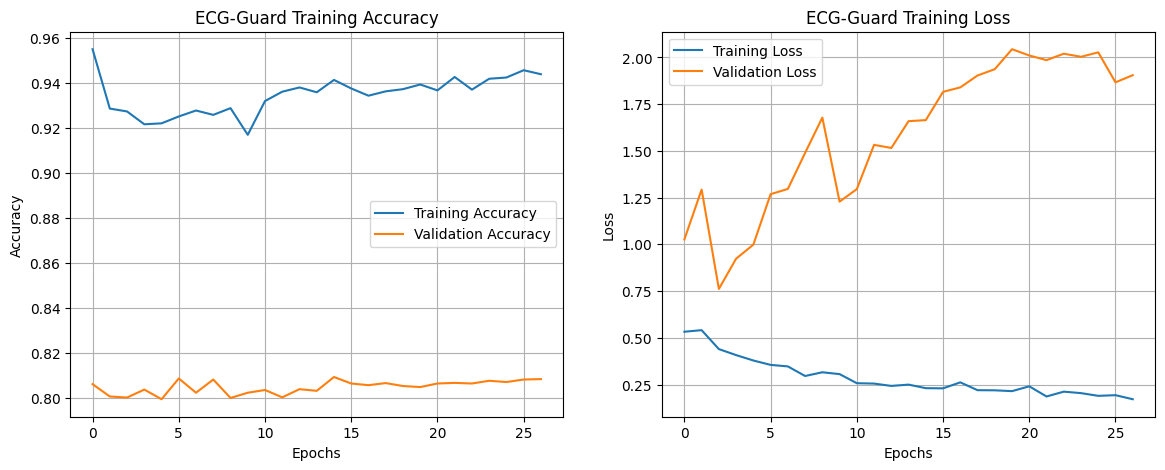

In [ ]:
#25

#plot accuracy and loss

plt.figure(figsize=(14,5))

#accuracy graph
plt.subplot(1,2,1)

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)


plt.plot(history.history["val_accuracy"],label="Validation Accuracy")


plt.title("ECG-Guard Training Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()

#loss graph
plt.subplot(1,2,2)

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(history.history["val_loss"],label="Validation Loss")

plt.title("ECG-Guard Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()

plt.show()

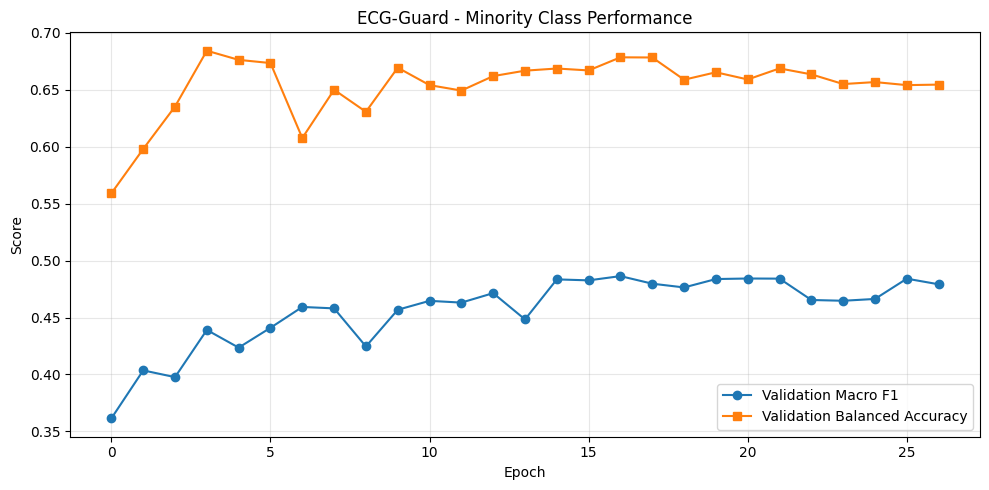

In [ ]:
#25A

plt.figure(figsize=(10, 5))

plt.plot(
    history.history["val_macro_f1"],
    marker="o",
    label="Validation Macro F1"
)

plt.plot(
    history.history["val_balanced_accuracy"],
    marker="s",
    label="Validation Balanced Accuracy"
)

plt.title("ECG-Guard - Minority Class Performance")

plt.xlabel("Epoch")
plt.ylabel("Score")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:
print("========== MODEL INPUTS ==========")

print("Model input shape:", model.input_shape)

print("\n========== TEST DATA SHAPES ==========")

print("X_test shape:", X_test.shape)
print("X_test dtype:", X_test.dtype)

print("RR_test shape:", RR_test.shape)
print("RR_test dtype:", RR_test.dtype)

print("\n========== DATA VALIDATION ==========")

print("ECG samples:", len(X_test))
print("RR samples:", len(RR_test))

print("Same number of samples:",
      len(X_test) == len(RR_test))

========== MODEL INPUTS ==========
Model input shape: [(None, 216, 1), (None, 4)]

========== TEST DATA SHAPES ==========
X_test shape: (47552, 216, 1)
X_test dtype: float32
RR_test shape: (47552, 4)
RR_test dtype: float32

========== DATA VALIDATION ==========
ECG samples: 47552
RR samples: 47552
Same number of samples: True


# evaluating the trained model

In [ ]:
#26

# Convert inputs to proper numerical arrays

X_test = np.asarray(
    X_test,
    dtype=np.float32
)

RR_test = np.asarray(
    RR_test,
    dtype=np.float32
)

# Ensure ECG has 3 dimensions

if X_test.ndim == 2:

    X_test = X_test[..., np.newaxis]


# Validate input dimensions

assert X_test.ndim == 3, "Incorrect ECG dimensions"

assert X_test.shape[1:] == (216, 1), \
    "Incorrect ECG input shape"

assert RR_test.ndim == 2, \
    "Incorrect RR feature dimensions"

assert RR_test.shape[1] == 4, \
    "Expected 4 RR features"

assert len(X_test) == len(RR_test), \
    "ECG and RR sample counts do not match"


# Generate predictions

y_prob = model.predict(
    [X_test, RR_test],
    batch_size=128,
    verbose=1
)

# Get predicted classes

y_pred = np.argmax(
    y_prob,
    axis=1
)

print("\nPrediction generated successfully!")

print("Prediction shape:", y_pred.shape)

print("Probability shape:", y_prob.shape)

372/372 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step

Prediction generated successfully!
Prediction shape: (47552,)
Probability shape: (47552, 4)


In [ ]:
#classification report

from sklearn.metrics import classification_report

print(classification_report(y_test_4,y_pred,labels=[0,1,2,3],target_names=CLASS_NAMES,zero_division=0))

                  precision    recall  f1-score   support

          Normal       0.96      0.89      0.93     42182
Supraventricular       0.19      0.27      0.22      1782
     Ventricular       0.87      0.94      0.90      3201
     Fusion Beat       0.01      0.05      0.01       387

        accuracy                           0.87     47552
       macro avg       0.51      0.54      0.52     47552
    weighted avg       0.92      0.87      0.89     47552



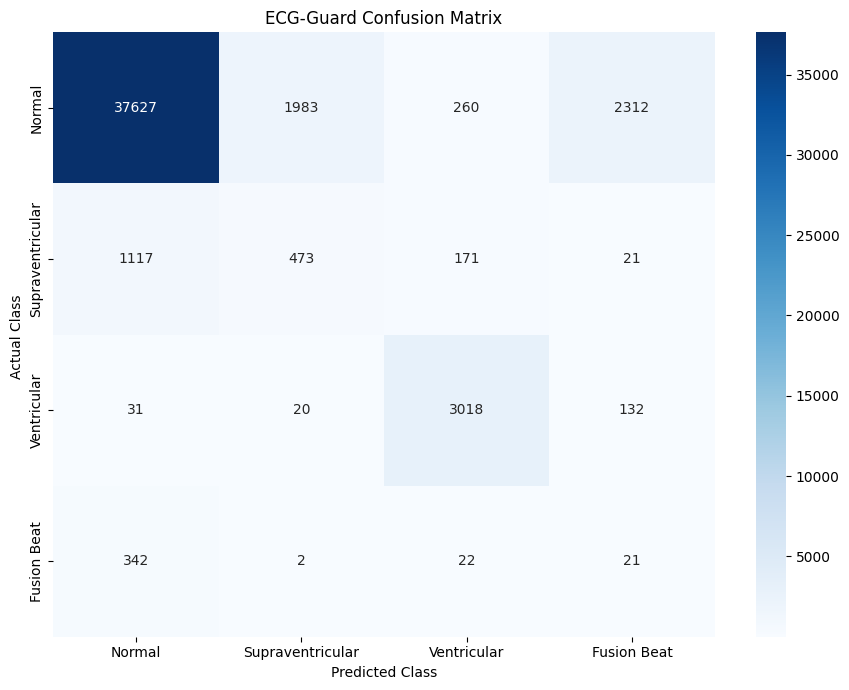

In [ ]:
#27

#generate the confusion matrix

from sklearn.metrics import confusion_matrix

cm=confusion_matrix(y_test_4,y_pred,labels=[0,1,2,3])

plt.figure(figsize=(9,7))

sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",xticklabels=CLASS_NAMES,yticklabels=CLASS_NAMES)

plt.title("ECG-Guard Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class ")


plt.tight_layout()
plt.show()

In [ ]:
#28



#calculate additional evaluation metrics

from sklearn.metrics import (accuracy_score,balanced_accuracy_score,f1_score,precision_score,recall_score)

accuracy=accuracy_score(y_test_4,y_pred)

balanced_acc=balanced_accuracy_score(y_test_4,y_pred)

macro_recall=recall_score(y_test_4,y_pred,average="macro",zero_division=0)

macro_precision=precision_score(y_test_4,y_pred,average="macro",zero_division=0)

macro_f1=f1_score(y_test_4,y_pred,average="macro",zero_division=0)

print("-----------------ECG Guard Performance-------------------")

print(f"Accuracy: {accuracy:.4f}")

print(f"Balanced Accuracy: {balanced_acc:.4f}")

print(f"Macro Recall: {macro_recall:.4f}")

print(f"Macro Precision: {macro_precision:.4f}")

print(f"Macro F1-Score: {macro_f1:.4f}")



-----------------ECG Guard Performance-------------------
Accuracy: 0.8651
Balanced Accuracy: 0.5386
Macro Recall: 0.5386
Macro Precision: 0.5077
Macro F1-Score: 0.5168


========== CLASS-WISE PERFORMANCE ==========
                  precision    recall  f1-score   support

          Normal     0.9619    0.8920    0.9256     42182
Supraventricular     0.1909    0.2654    0.2221      1782
     Ventricular     0.8695    0.9428    0.9047      3201
     Fusion Beat     0.0084    0.0543    0.0146       387

        accuracy                         0.8651     47552
       macro avg     0.5077    0.5386    0.5168     47552
    weighted avg     0.9190    0.8651    0.8905     47552



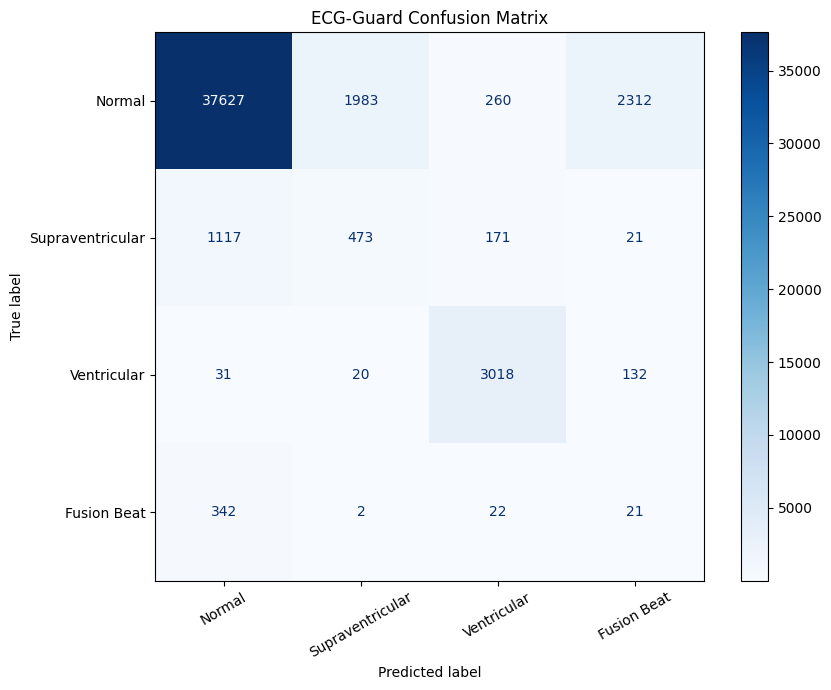


========== PREDICTION DISTRIBUTION ==========
Normal : 39117
Supraventricular : 2478
Ventricular : 3471
Fusion Beat : 2486


In [ ]:
#28A


from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

# Detailed classification report

print("========== CLASS-WISE PERFORMANCE ==========")

print(
    classification_report(
        y_test_4,
        y_pred,
        labels=[0, 1, 2, 3],
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)


# Confusion Matrix

cm = confusion_matrix(
    y_test_4,
    y_pred,
    labels=[0, 1, 2, 3]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
)

fig, ax = plt.subplots(figsize=(9, 7))

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d"
)

plt.title("ECG-Guard Confusion Matrix")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


# Prediction distribution

print("\n========== PREDICTION DISTRIBUTION ==========")

for i, name in enumerate(CLASS_NAMES):

    print(
        name,
        ":",
        np.sum(y_pred == i)
    )

In [ ]:
#28B

# ==========================================
# TRAINING AND VALIDATION DISTRIBUTION AUDIT
# ==========================================

train_groups = groups_train_4[train_idx]
val_groups = groups_train_4[val_idx]

print("========== CLASS DISTRIBUTION ==========")

for cls, name in enumerate(CLASS_NAMES):

    train_count = np.sum(y_train == cls)
    val_count = np.sum(y_val == cls)

    train_patients = len(
        np.unique(train_groups[y_train == cls])
    )

    val_patients = len(
        np.unique(val_groups[y_val == cls])
    )

    print(f"\n{name}")

    print("Training samples:", train_count)
    print("Validation samples:", val_count)

    print("Training patients:", train_patients)
    print("Validation patients:", val_patients)


print("\n========== CLASS MAPPING ==========")

print(CLASS_MAP)


print("\n========== CLASS WEIGHTS ==========")

print(class_weights)

========== CLASS DISTRIBUTION ==========

Normal
Training samples: 34460
Validation samples: 9757
Training patients: 16
Validation patients: 5

Supraventricular
Training samples: 626
Validation samples: 190
Training patients: 10
Validation patients: 5

Ventricular
Training samples: 2819
Validation samples: 771
Training patients: 12
Validation patients: 4

Fusion Beat
Training samples: 385
Validation samples: 27
Training patients: 6
Validation patients: 3

========== CLASS MAPPING ==========
{'N': 0, 'L': 0, 'R': 0, 'e': 0, 'j': 0, 'A': 1, 'a': 1, 'J': 1, 'S': 1, 'V': 2, 'E': 2, 'F': 3, '/': 4, 'f': 4, 'Q': 4, 'U': 4}

========== CLASS WEIGHTS ==========
{0: 0.5270539238574278, 1: 3.910439047770196, 2: 1.8427446100220086, 3: 4.986344990435015}


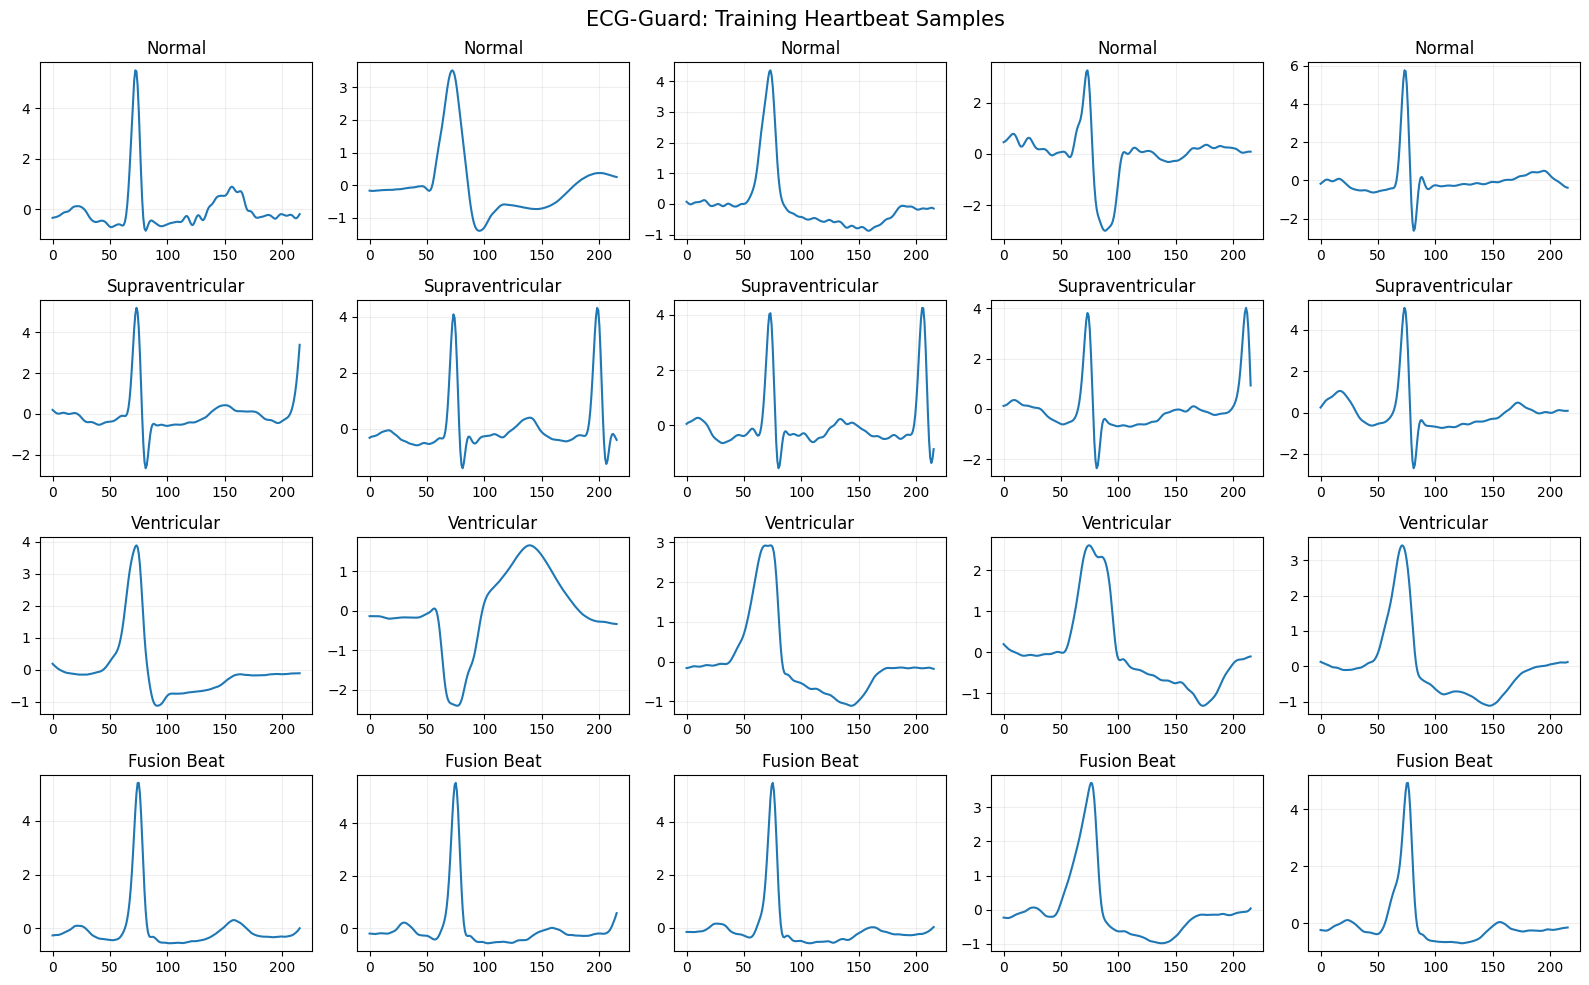

In [ ]:
#28 C

import matplotlib.pyplot as plt
import numpy as np

np.random.seed(42)

fig, axes = plt.subplots(
    4, 5,
    figsize=(16, 10)
)

for cls in range(4):

    indices = np.where(y_train == cls)[0]

    selected = np.random.choice(
        indices,
        size=min(5, len(indices)),
        replace=False
    )

    for j, idx in enumerate(selected):

        axes[cls, j].plot(
            X_train[idx, :, 0]
        )

        axes[cls, j].set_title(
            CLASS_NAMES[cls]
        )

        axes[cls, j].grid(alpha=0.2)

plt.suptitle(
    "ECG-Guard: Training Heartbeat Samples",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [ ]:
#28 D

# ==========================================
# PATIENT-WISE CLASS DISTRIBUTION
# ==========================================

patient_counts = pd.crosstab(
    groups_train_4,
    y_train_all_4
)

patient_counts = patient_counts.reindex(
    columns=[0, 1, 2, 3],
    fill_value=0
)

patient_counts.columns = CLASS_NAMES

patient_counts["Total"] = patient_counts.sum(axis=1)

# Sort patients by Fusion Beat count

patient_counts = patient_counts.sort_values(
    by="Fusion Beat",
    ascending=False
)

print("========== PATIENT-WISE DISTRIBUTION ==========")

display(patient_counts)

print("\nPatients containing each class:")

print(
    (patient_counts[CLASS_NAMES] > 0).sum()
)

========== PATIENT-WISE DISTRIBUTION ==========


,Normal,Supraventricular,Ventricular,Fusion Beat,Total
row_0,,,,,
208,1585,2,992,372,2951
223,2045,73,473,14,2605
205,2570,3,71,11,2655
124,1535,31,47,5,1618
114,1820,12,43,4,1879
108,1740,4,17,2,1763
109,2491,0,38,2,2531
203,2529,2,444,1,2976
215,3194,3,164,1,3362



Patients containing each class:
Normal              21
Supraventricular    15
Ventricular         16
Fusion Beat          9
dtype: int64


In [ ]:
#28E

# ==========================================
# PATIENT-WISE VALIDATION PERFORMANCE
# ==========================================

from sklearn.metrics import recall_score, f1_score

val_groups = np.asarray(
    groups_all
)[val_idx].astype(str)

print("========== PATIENT-WISE VALIDATION ==========")

for patient in np.unique(val_groups):

    mask = val_groups == patient

    actual = y_val[mask]

    predicted = val_pred[mask]

    print("\nPatient:", patient)

    for cls, name in enumerate(CLASS_NAMES):

        support = np.sum(actual == cls)

        predicted_count = np.sum(predicted == cls)

        correct = np.sum(
            (actual == cls) &
            (predicted == cls)
        )

        recall = (
            correct / support
            if support > 0
            else 0
        )

        print(
            name,
            "| Actual:", support,
            "| Predicted:", predicted_count,
            "| Recall:", round(recall, 4)
        )

========== PATIENT-WISE VALIDATION ==========

Patient: 101
Normal | Actual: 1860 | Predicted: 1861 | Recall: 1.0
Supraventricular | Actual: 3 | Predicted: 0 | Recall: 0.0
Ventricular | Actual: 0 | Predicted: 2 | Recall: 0
Fusion Beat | Actual: 0 | Predicted: 0 | Recall: 0

Patient: 108
Normal | Actual: 1740 | Predicted: 1506 | Recall: 0.8649
Supraventricular | Actual: 4 | Predicted: 18 | Recall: 0.75
Ventricular | Actual: 17 | Predicted: 76 | Recall: 0.7059
Fusion Beat | Actual: 2 | Predicted: 163 | Recall: 0.0

Patient: 205
Normal | Actual: 2570 | Predicted: 2566 | Recall: 0.9965
Supraventricular | Actual: 3 | Predicted: 5 | Recall: 1.0
Ventricular | Actual: 71 | Predicted: 65 | Recall: 0.9155
Fusion Beat | Actual: 11 | Predicted: 19 | Recall: 0.5455

Patient: 207
Normal | Actual: 1542 | Predicted: 105 | Recall: 0.0597
Supraventricular | Actual: 107 | Predicted: 0 | Recall: 0.0
Ventricular | Actual: 210 | Predicted: 828 | Recall: 0.9238
Fusion Beat | Actual: 0 | Predicted: 926 | Reca

========== VALIDATION METRICS AUDIT ==========
Accuracy: 0.8171
Balanced Accuracy: 0.5722
Macro Precision: 0.559
Macro Recall: 0.5722
Macro F1: 0.4943

========== PATIENT ECG LEAD AUDIT ==========
Patient: 101 | Available leads: ['MLII', 'V1'] | Selected lead: MLII
Patient: 108 | Available leads: ['MLII', 'V1'] | Selected lead: MLII
Patient: 205 | Available leads: ['MLII', 'V1'] | Selected lead: MLII
Patient: 207 | Available leads: ['MLII', 'V1'] | Selected lead: MLII
Patient: 223 | Available leads: ['MLII', 'V1'] | Selected lead: MLII

========== PATIENT INPUT AUDIT ==========

Patient: 101
Actual distribution: [1860    3    0    0]
Predicted distribution: [1861    0    2    0]
Mean predicted probabilities: [0.976 0.013 0.002 0.009]
RR feature means: [ 1.101  1.1   -0.055 -0.055]
RR feature standard deviations: [0.365 0.365 0.433 0.432]
Median normalized ECG peak: 5.476

Patient: 108
Actual distribution: [1740    4   17    2]
Predicted distribution: [1506   18   76  163]
Mean predicte

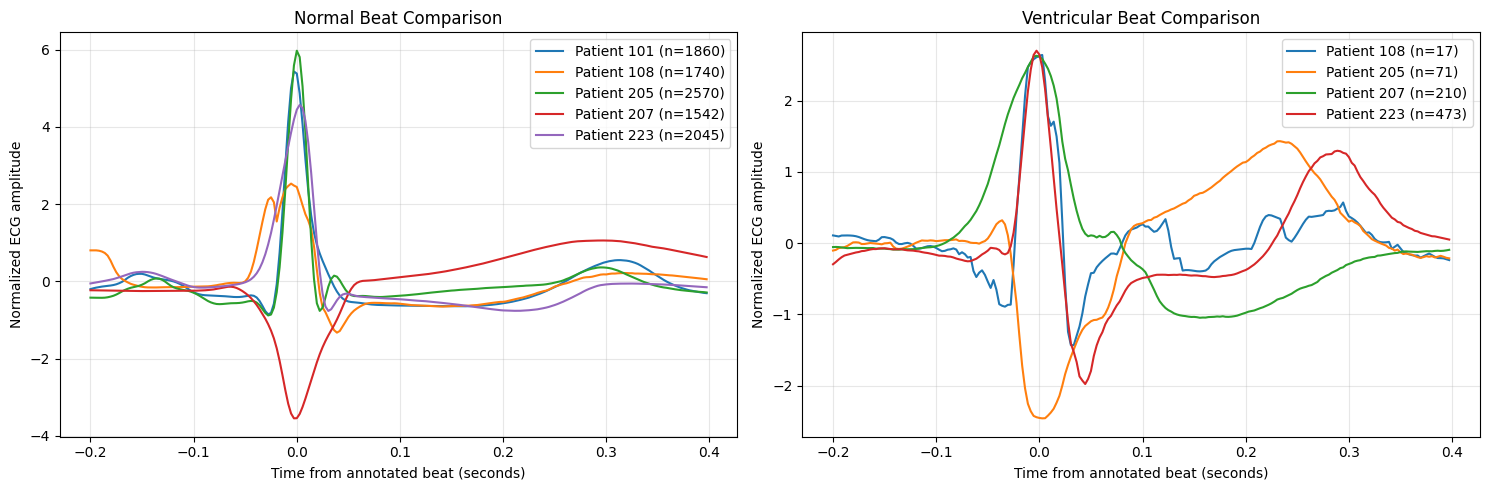

In [ ]:

#28F
import os
import wfdb
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# --------------------------------------------------
# STEP 1: Generate validation predictions
# --------------------------------------------------

val_groups = np.asarray(groups_all)[val_idx].astype(str)

val_prob_diag = model.predict(
    val_inputs,
    batch_size=512,
    verbose=0
)

val_pred_diag = np.argmax(
    val_prob_diag,
    axis=1
)

print("========== VALIDATION METRICS AUDIT ==========")

print("Accuracy:",
      round(accuracy_score(y_val, val_pred_diag), 4))

print("Balanced Accuracy:",
      round(balanced_accuracy_score(y_val, val_pred_diag), 4))

print("Macro Precision:",
      round(precision_score(
          y_val, val_pred_diag,
          average="macro",
          zero_division=0
      ), 4))

print("Macro Recall:",
      round(recall_score(
          y_val, val_pred_diag,
          average="macro",
          zero_division=0
      ), 4))

print("Macro F1:",
      round(f1_score(
          y_val, val_pred_diag,
          average="macro",
          zero_division=0
      ), 4))


# --------------------------------------------------
# STEP 2: Check ECG lead configuration
# --------------------------------------------------

print("\n========== PATIENT ECG LEAD AUDIT ==========")

for patient in np.unique(val_groups):

    record_id = str(patient).zfill(3)

    record_path = os.path.join(
        RAW_DIR,
        record_id
    )

    record = wfdb.rdrecord(record_path)

    lead_names = [
        name.upper()
        for name in record.sig_name
    ]

    selected_index = next(
        (
            i for i, name in enumerate(lead_names)
            if "MLII" in name
        ),
        0
    )

    print(
        "Patient:", record_id,
        "| Available leads:", record.sig_name,
        "| Selected lead:", record.sig_name[selected_index]
    )


# --------------------------------------------------
# STEP 3: Patient-wise input and prediction audit
# --------------------------------------------------

X_val_flat = X_val.reshape(len(X_val), -1)

print("\n========== PATIENT INPUT AUDIT ==========")

for patient in np.unique(val_groups):

    mask = val_groups == patient

    actual = y_val[mask]
    predicted = val_pred_diag[mask]

    actual_counts = np.bincount(
        actual,
        minlength=4
    )

    predicted_counts = np.bincount(
        predicted,
        minlength=4
    )

    print("\nPatient:", patient)

    print("Actual distribution:", actual_counts)
    print("Predicted distribution:", predicted_counts)

    print(
        "Mean predicted probabilities:",
        np.round(
            val_prob_diag[mask].mean(axis=0),
            3
        )
    )

    print(
        "RR feature means:",
        np.round(RR_val[mask].mean(axis=0), 3)
    )

    print(
        "RR feature standard deviations:",
        np.round(RR_val[mask].std(axis=0), 3)
    )

    beat_peaks = np.max(
        np.abs(X_val_flat[mask]),
        axis=1
    )

    print(
        "Median normalized ECG peak:",
        round(float(np.median(beat_peaks)), 3)
    )


# --------------------------------------------------
# STEP 4: Compare heartbeat morphology
# --------------------------------------------------

time_axis = np.arange(X_val.shape[1]) / 360 - 0.2

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 5)
)

for ax, cls, class_name in zip(
    axes,
    [0, 2],
    ["Normal", "Ventricular"]
):

    for patient in np.unique(val_groups):

        mask = (
            (val_groups == patient) &
            (y_val == cls)
        )

        if np.sum(mask) == 0:
            continue

        patient_beats = X_val[mask].squeeze(-1)

        median_template = np.median(
            patient_beats,
            axis=0
        )

        ax.plot(
            time_axis,
            median_template,
            label=f"Patient {patient} (n={len(patient_beats)})"
        )

    ax.set_title(f"{class_name} Beat Comparison")
    ax.set_xlabel("Time from annotated beat (seconds)")
    ax.set_ylabel("Normalized ECG amplitude")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:

# STEP: CONNECT TO THE V3 DATASET

from google.colab import drive
drive.mount('/content/drive')

import numpy as np
import pandas as pd
from pathlib import Path

DATA_DIR = Path(
    "/content/drive/MyDrive/ECG_Guard_Dataset_V2/processed_v3"
)

# Check important files
files = [
    "X_train_balanced_v3.npy",
    "y_train_balanced_v3.npy",
    "X_validation_v3.npy",
    "y_validation_v3.npy",
    "X_test_v3.npy",
    "y_test_v3.npy",
    "beat_metadata_v3.csv",
    "balanced_training_metadata_v3.csv"
]

print("========== FILE CHECK ==========")

for filename in files:
    filepath = DATA_DIR / filename
    print(filename, ":", filepath.exists())

# Inspect array shapes without loading everything into RAM
print("\n========== ARRAY SHAPES ==========")

for filename in files[:6]:
    filepath = DATA_DIR / filename
    if filepath.exists():
        arr = np.load(filepath, mmap_mode="r")
        print(filename, ":", arr.shape, arr.dtype)

# Load metadata
beat_meta = pd.read_csv(
    DATA_DIR / "beat_metadata_v3.csv",
    low_memory=False
)

balanced_meta = pd.read_csv(
    DATA_DIR / "balanced_training_metadata_v3.csv",
    low_memory=False
)

print("\n========== ORIGINAL BEAT METADATA ==========")
print("Shape:", beat_meta.shape)
print("Columns:", beat_meta.columns.tolist())
display(beat_meta.head(5).T)

print("\n========== BALANCED TRAINING METADATA ==========")
print("Shape:", balanced_meta.shape)
print("Columns:", balanced_meta.columns.tolist())
display(balanced_meta.head(5).T)

if "is_augmented" in balanced_meta.columns:
    print("\n========== AUGMENTATION AUDIT ==========")
    print(balanced_meta["is_augmented"].value_counts(dropna=False))
    display(
        balanced_meta[
            balanced_meta["is_augmented"].astype(str).str.lower()
            .isin(["true", "1", "yes"])
        ].head(5).T
    )
